# Cognitive Task Exploratory Factor Analysis

Run matched exploratory factor analysis workflows (with and without residualizing for SES)

In [15]:
import pandas as pd
import numpy as np
from pathlib import Path
import inspect
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from scipy import stats
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
import factor_analyzer.factor_analyzer as factor_analyzer_module
from sklearn.linear_model import LinearRegression
import seaborn as sns

# Needed bc factor_analyzer was renamed in newer sklean releases
if 'force_all_finite' not in inspect.signature(factor_analyzer_module.check_array).parameters:
    _sklearn_check_array = factor_analyzer_module.check_array

    def _factor_analyzer_check_array(*args, force_all_finite=True, **kwargs):
        kwargs.setdefault('ensure_all_finite', force_all_finite)
        return _sklearn_check_array(*args, **kwargs)

    factor_analyzer_module.check_array = _factor_analyzer_check_array


sns.set_style('whitegrid')
sns.set_palette('colorblind')
palette = sns.color_palette('colorblind')
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 26,
    'axes.labelsize': 22,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
})

In [16]:
INVALID_CODES = (555, 777, 888, 999)

DEFAULT_CATEGORICAL_COVARIATES = {
    'demo_sex_v2',
    'site_id_l',
    'ehi1b',
}


def standardize_subject_id(subject_ids):
    return (
        subject_ids.astype(str)
        .str.replace('_', '', regex=False)
        .str.replace('^sub-', '', regex=True)
    )


def load_motion_qa(motion_qa_path, motion_column='mean_fd_0.20'):
    motion_qa = pd.read_csv(motion_qa_path)
    motion_qa = motion_qa[['src_subject_id', motion_column]].copy()
    motion_qa['src_subject_id'] = standardize_subject_id(motion_qa['src_subject_id'])
    motion_qa = motion_qa.drop_duplicates(subset=['src_subject_id'])
    motion_qa[motion_column] = pd.to_numeric(motion_qa[motion_column], errors='coerce')
    return motion_qa


def merge_motion_qa(df, motion_qa_path, motion_column='mean_fd_0.20', how='left'):
    motion_qa = load_motion_qa(motion_qa_path, motion_column=motion_column)

    merged = df.copy()
    merged['src_subject_id'] = standardize_subject_id(merged['src_subject_id'])
    if motion_column in merged.columns:
        existing_motion = merged.groupby('src_subject_id')[motion_column].first()
        merged = merged.drop(columns=[motion_column])
        merged = merged.merge(motion_qa, on='src_subject_id', how=how)
        merged[motion_column] = merged[motion_column].fillna(
            merged['src_subject_id'].map(existing_motion)
        )
    else:
        merged = merged.merge(motion_qa, on='src_subject_id', how=how)
    return merged


def _encode_regression_covariates(df, covariates, categorical_covariates=DEFAULT_CATEGORICAL_COVARIATES):
    encoded_parts = []
    categorical_covariates = set(categorical_covariates)

    for covariate in covariates:
        if df[covariate].dtype == 'object' or covariate in categorical_covariates:
            encoded_parts.append(
                pd.get_dummies(
                    df[covariate],
                    prefix=covariate,
                    drop_first=True,
                    dtype=float,
                )
            )
        else:
            encoded_parts.append(
                pd.to_numeric(df[covariate], errors='coerce').to_frame(covariate)
            )

    return pd.concat(encoded_parts, axis=1)


def residualize_measure(df, measure, covariates, output_col=None, invalid_codes=INVALID_CODES):
    df = df.copy()
    output_col = output_col or f'{measure}_resid'
    if output_col in df.columns:
        df = df.drop(columns=[output_col])

    temp_df = df[['src_subject_id', measure, *covariates]].copy()
    temp_df[measure] = temp_df[measure].replace(list(invalid_codes), np.nan)
    temp_df = temp_df.dropna()

    if len(temp_df) == 0:
        df[output_col] = np.nan
        return df

    covariate_matrix = _encode_regression_covariates(temp_df, covariates)
    if covariate_matrix.shape[1] == 0:
        predicted = np.repeat(temp_df[measure].mean(), len(temp_df))
    else:
        model = LinearRegression().fit(covariate_matrix, temp_df[measure])
        predicted = model.predict(covariate_matrix)
    temp_df[output_col] = temp_df[measure] - predicted

    return df.merge(
        temp_df[['src_subject_id', output_col]],
        on='src_subject_id',
        how='left',
    )


In [17]:
DATA_PATH = '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/wrangled_pMTG_FC_data_fullnetworks_meanFC.csv'
MOTION_QA_PATH = '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/motion_QA_results.csv'
EFA_RESULTS_DIR = Path('/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/efa_results')
EFA_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = merge_motion_qa(df, MOTION_QA_PATH, how='left')
print(f'Loaded {len(df)} rows from {DATA_PATH}')

Loaded 2472 rows from /Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/wrangled_pMTG_FC_data_fullnetworks_meanFC.csv


## Task Analysis Settings

The SES model residualizes raw cognitive measures once with INR included alongside the standard covariates.

In [18]:
SES_VARIABLE = 'inr'
SES_RESIDUALIZATION_COVARIATE = 'inr'
INVALID_CODES = (555, 777, 888, 999)
EFA_N_FACTORS = None  # None uses the Kaiser rule: retain factors with eigenvalue > 1.
EFA_ROTATION = 'oblimin'
EFA_METHOD = 'ml'

COGNITIVE_TASK_MEASURES = [
    'ravlt_immediate_2y',
    'ravlt_short_delay_2y',
    'ravlt_long_delay_2y',
    'nihtbx_picvocab_uncorrected_2y',
    'nihtbx_reading_uncorrected_2y',
    'nihtbx_picture_uncorrected_2y'
]

column_names_to_tasks = {
    'ravlt_immediate_2y': 'RAVLT Immediate Recall',
    'ravlt_short_delay_2y': 'RAVLT Short Delayed Recall',
    'ravlt_long_delay_2y': 'RAVLT Long Delayed Recall',
    'nihtbx_picvocab_uncorrected_2y': 'Picture Vocabulary',
    'nihtbx_reading_uncorrected_2y': 'Oral Reading Recognition',
    'nihtbx_picture_uncorrected_2y': 'Picture Sequence Memory'
}

COGNITIVE_TASK_COVARIATES = ['interview_age', 'demo_sex_v2', 'site_id_l', 'ehi1b']
EFA_MODEL_SPECS = [
    {
        'model_name': 'without_ses_residualization',
        'label': 'No SES residualization',
        'short_label': 'No SES',
        'prefix': 'no_ses',
        'cognitive_covariates': COGNITIVE_TASK_COVARIATES,
    },
    {
        'model_name': 'with_ses_residualization',
        'label': 'SES residualization',
        'short_label': 'SES',
        'prefix': 'ses',
        'cognitive_covariates': COGNITIVE_TASK_COVARIATES + [SES_RESIDUALIZATION_COVARIATE],
    },
]

print('Task EFA model specs:')
for spec in EFA_MODEL_SPECS:
    print(f"- {spec['model_name']}")
    print(f"  Cognitive covariates: {spec['cognitive_covariates']}")
print(f'EFA factor count: {EFA_N_FACTORS if EFA_N_FACTORS is not None else "Kaiser eigenvalue > 1 rule"}')
print(f'EFA method: {EFA_METHOD}; rotation: {EFA_ROTATION}')

Task EFA model specs:
- without_ses_residualization
  Cognitive covariates: ['interview_age', 'demo_sex_v2', 'site_id_l', 'ehi1b']
- with_ses_residualization
  Cognitive covariates: ['interview_age', 'demo_sex_v2', 'site_id_l', 'ehi1b', 'inr']
EFA factor count: Kaiser eigenvalue > 1 rule
EFA method: ml; rotation: oblimin


## EFA Helpers

In [22]:
def residualize_cognitive_variant(data, measures, covariates, output_suffix):
    residualized = data
    output_cols = []
    for measure in measures:
        output_col = f'{measure}_{output_suffix}_resid'
        residualized = residualize_measure(
            residualized,
            measure=measure,
            covariates=covariates,
            output_col=output_col,
            invalid_codes=INVALID_CODES,
        )
        output_cols.append(output_col)
    return residualized, output_cols


def attach_score_columns(data, scores):
    updated = data.copy()
    for score_col in scores.columns:
        updated[score_col] = scores[score_col]
    return updated


def factorability_diagnostics(efa_complete):
    diagnostics = {}
    try:
        bartlett_chi_square, bartlett_p_value = calculate_bartlett_sphericity(efa_complete)
    except Exception as exc:
        print(f'Bartlett sphericity test failed: {exc}')
        bartlett_chi_square, bartlett_p_value = np.nan, np.nan
    try:
        kmo_per_item, kmo_overall = calculate_kmo(efa_complete)
    except Exception as exc:
        print(f'KMO calculation failed: {exc}')
        kmo_per_item = np.full(efa_complete.shape[1], np.nan)
        kmo_overall = np.nan

    diagnostics['bartlett_chi_square'] = bartlett_chi_square
    diagnostics['bartlett_p_value'] = bartlett_p_value
    diagnostics['kmo_overall'] = kmo_overall
    diagnostics['kmo_per_item'] = pd.Series(kmo_per_item, index=efa_complete.columns, name='kmo')
    return diagnostics


def choose_efa_factor_count(eigenvalues, requested_n_factors=None):
    max_factors = max(1, len(eigenvalues) - 1)
    if requested_n_factors is None:
        selected = int(np.sum(np.asarray(eigenvalues) > 1.0))
        selection_rule = 'kaiser_eigenvalue_gt_1'
        if selected < 1:
            selected = 1
            selection_rule = 'kaiser_fallback_1_factor'
    else:
        selected = int(requested_n_factors)
        selection_rule = 'user_specified'

    selected = min(max(selected, 1), max_factors)
    return selected, selection_rule


def fit_efa_scores(
    data,
    feature_cols,
    score_prefix,
    n_factors=None,
    rotation='oblimin',
    method='ml',
):
    efa_input = data[feature_cols].apply(pd.to_numeric, errors='coerce')
    efa_complete = efa_input.dropna().copy()
    print(f'{score_prefix} EFA complete cases: {len(efa_complete)}/{len(efa_input)}')

    scaler = StandardScaler()
    efa_matrix = pd.DataFrame(
        scaler.fit_transform(efa_complete),
        index=efa_complete.index,
        columns=feature_cols,
    )

    eigen_model = FactorAnalyzer(rotation=None, method=method, svd_method='lapack')
    eigen_model.fit(efa_matrix)
    eigenvalues, common_factor_eigenvalues = eigen_model.get_eigenvalues()
    selected_n_factors, selection_rule = choose_efa_factor_count(eigenvalues, n_factors)

    efa = FactorAnalyzer(
        n_factors=selected_n_factors,
        rotation=rotation,
        method=method,
        svd_method='lapack',
    )
    efa.fit(efa_matrix)
    factor_score_array = efa.transform(efa_matrix)
    factor_cols = [f'{score_prefix}_EF{i + 1}' for i in range(selected_n_factors)]

    scores = pd.DataFrame(np.nan, index=data.index, columns=factor_cols, dtype=float)
    scores.loc[efa_complete.index, factor_cols] = factor_score_array

    loadings = pd.DataFrame(efa.loadings_, index=feature_cols, columns=factor_cols)
    uniquenesses = pd.Series(efa.get_uniquenesses(), index=feature_cols, name='uniqueness')
    communalities = pd.Series(efa.get_communalities(), index=feature_cols, name='communality')
    measure_diagnostics = pd.concat([communalities, uniquenesses], axis=1)

    variance_values, proportional_variance, cumulative_variance = efa.get_factor_variance()
    variance = pd.DataFrame({
        'factor': factor_cols,
        'ss_loadings': variance_values,
        'proportional_variance': proportional_variance,
        'cumulative_variance': cumulative_variance,
    })

    eigenvalues_table = pd.DataFrame({
        'component': np.arange(1, len(eigenvalues) + 1),
        'eigenvalue': eigenvalues,
        'common_factor_eigenvalue': common_factor_eigenvalues,
        'retained_by_kaiser_rule': eigenvalues > 1.0,
    })

    factorability = factorability_diagnostics(efa_complete)
    diagnostics = pd.DataFrame([
        {
            'score_prefix': score_prefix,
            'n_complete': len(efa_complete),
            'n_measures': len(feature_cols),
            'n_factors': selected_n_factors,
            'factor_selection_rule': selection_rule,
            'rotation': rotation,
            'method': method,
            'bartlett_chi_square': factorability['bartlett_chi_square'],
            'bartlett_p_value': factorability['bartlett_p_value'],
            'kmo_overall': factorability['kmo_overall'],
        }
    ])
    kmo_per_item = factorability['kmo_per_item'].to_frame()

    return {
        'input': efa_input,
        'complete_input': efa_complete,
        'standardized_input': efa_matrix,
        'efa': efa,
        'score_cols': factor_cols,
        'scores': scores,
        'loadings': loadings,
        'variance': variance,
        'eigenvalues': eigenvalues_table,
        'diagnostics': diagnostics,
        'measure_diagnostics': measure_diagnostics,
        'kmo_per_item': kmo_per_item,
    }


def plot_cognitive_efa_summary(efa_result, labels, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    eigenvalues = efa_result['eigenvalues']
    axes[0].plot(
        eigenvalues['component'],
        eigenvalues['eigenvalue'],
        marker='o',
        color='black',
    )
    axes[0].axhline(1.0, color=palette[1], linestyle='--', linewidth=1.0, label='Eigenvalue = 1')
    axes[0].set_xlabel('Factor Number', fontsize=16)
    axes[0].set_ylabel('Eigenvalue', fontsize=16)
    axes[0].set_title(title, fontsize=20)
    axes[0].set_xticks(eigenvalues['component'])
    axes[0].legend(frameon=False)

    heatmap = sns.heatmap(
        efa_result['loadings'],
        ax=axes[1],
        center=0,
        cmap='vlag',
        annot=True,
        fmt='.2f',
        cbar_kws={'label': 'Rotated Loading'},
    )

    # Set colorbar label font size separately
    colorbar = heatmap.collections[0].colorbar
    colorbar.ax.yaxis.label.set_size(14)
    colorbar.ax.tick_params(labelsize=12)

    axes[1].set_title('Factor Loadings for Latent Retrieval Variables', fontsize=16)
    axes[1].set_xlabel('Exploratory Factor', fontsize=14)
    axes[1].set_xticks(np.arange(len(efa_result['score_cols'])) + 0.5)
    axes[1].set_xticklabels(
        [col.split('_')[-1] for col in efa_result['score_cols']],
        rotation=0,
        fontsize=14,
    )
    axes[1].set_yticks(np.arange(len(labels)) + 0.5)
    axes[1].set_yticklabels(labels, rotation=0, fontsize=14)
    axes[1].set_ylabel('Cognitive Task Measure', fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close()


def task_labels_for_residual_cols(cols, output_suffix):
    suffix = f'_{output_suffix}_resid'
    return [
        column_names_to_tasks.get(col.removesuffix(suffix), col)
        for col in cols
    ]


def plot_cognitive_measure_correlations(efa_input, feature_cols, labels, title):
    correlations = efa_input[feature_cols].corr(method='pearson')
    pairwise_n = efa_input[feature_cols].notna().astype(int).T.dot(
        efa_input[feature_cols].notna().astype(int)
    )

    print(f'{title}')
    display(correlations)

    plt.figure(figsize=(11, 9))
    sns.heatmap(
        correlations,
        vmin=-1,
        vmax=1,
        center=0,
        cmap='vlag',
        annot=True,
        fmt='.2f',
        square=True,
        cbar_kws={'label': 'Pearson r'},
    )
    plt.title(title, fontsize=20)
    plt.xticks(
        ticks=np.arange(len(feature_cols)) + 0.5,
        labels=labels,
        rotation=45,
        ha='right',
        fontsize=16,
    )
    plt.yticks(
        ticks=np.arange(len(feature_cols)) + 0.5,
        labels=labels,
        rotation=0,
        fontsize=16,
    )
    plt.tight_layout()
    plt.show()
    plt.close()

    return correlations, pairwise_n

## Matched Task EFA Workflows


No SES residualization
Cognitive covariates: ['interview_age', 'demo_sex_v2', 'site_id_l', 'ehi1b']
no_ses_cognitive EFA complete cases: 2229/2472

Cognitive EFA diagnostics:


,score_prefix,n_complete,n_measures,n_factors,factor_selection_rule,rotation,method,bartlett_chi_square,bartlett_p_value,kmo_overall
0,no_ses_cognitive,2229,6,2,kaiser_eigenvalue_gt_1,oblimin,ml,5307.972238,0.0,0.775674



Cognitive EFA eigenvalues:


,component,eigenvalue,common_factor_eigenvalue,retained_by_kaiser_rule
0,1,3.027789,2.737042,True
1,2,1.172943,0.777423,True
2,3,0.788156,0.133853,False
3,4,0.466940,0.008576,False
4,5,0.332108,-0.000655,False
5,6,0.212064,-0.007640,False



Cognitive EFA variance:


...

,no_ses_cognitive_EF1,no_ses_cognitive_EF2
ravlt_immediate_2y_no_ses_resid,0.736315,0.114369
ravlt_short_delay_2y_no_ses_resid,0.896290,-0.033391
ravlt_long_delay_2y_no_ses_resid,0.903568,-0.029689
nihtbx_picvocab_uncorrected_2y_no_ses_resid,0.021615,0.715480
nihtbx_reading_uncorrected_2y_no_ses_resid,-0.012369,0.740342
nihtbx_picture_uncorrected_2y_no_ses_resid,0.334467,0.134455



Cognitive EFA measure diagnostics:


,communality,uniqueness,kmo
ravlt_immediate_2y_no_ses_resid,0.555240,0.444760,0.854952
ravlt_short_delay_2y_no_ses_resid,0.804451,0.195549,0.755693
ravlt_long_delay_2y_no_ses_resid,0.817317,0.182683,0.754364
nihtbx_picvocab_uncorrected_2y_no_ses_resid,0.512379,0.487621,0.709175
nihtbx_reading_uncorrected_2y_no_ses_resid,0.548259,0.451741,0.695229
nihtbx_picture_uncorrected_2y_no_ses_resid,0.129946,0.870054,0.936136


Correlations Between Cognitive Tasks


,ravlt_immediate_2y_no_ses_resid,ravlt_short_delay_2y_no_ses_resid,ravlt_long_delay_2y_no_ses_resid,nihtbx_picvocab_uncorrected_2y_no_ses_resid,nihtbx_reading_uncorrected_2y_no_ses_resid,nihtbx_picture_uncorrected_2y_no_ses_resid
ravlt_immediate_2y_no_ses_resid,1.000000,0.688054,0.692758,0.321195,0.310721,0.343979
ravlt_short_delay_2y_no_ses_resid,0.688054,1.000000,0.789087,0.277243,0.247496,0.327522
ravlt_long_delay_2y_no_ses_resid,0.692758,0.789087,1.000000,0.275646,0.261565,0.349632
nihtbx_picvocab_uncorrected_2y_no_ses_resid,0.321195,0.277243,0.275646,1.000000,0.539864,0.213433
nihtbx_reading_uncorrected_2y_no_ses_resid,0.310721,0.247496,0.261565,0.539864,1.000000,0.192123
nihtbx_picture_uncorrected_2y_no_ses_resid,0.343979,0.327522,0.349632,0.213433,0.192123,1.000000


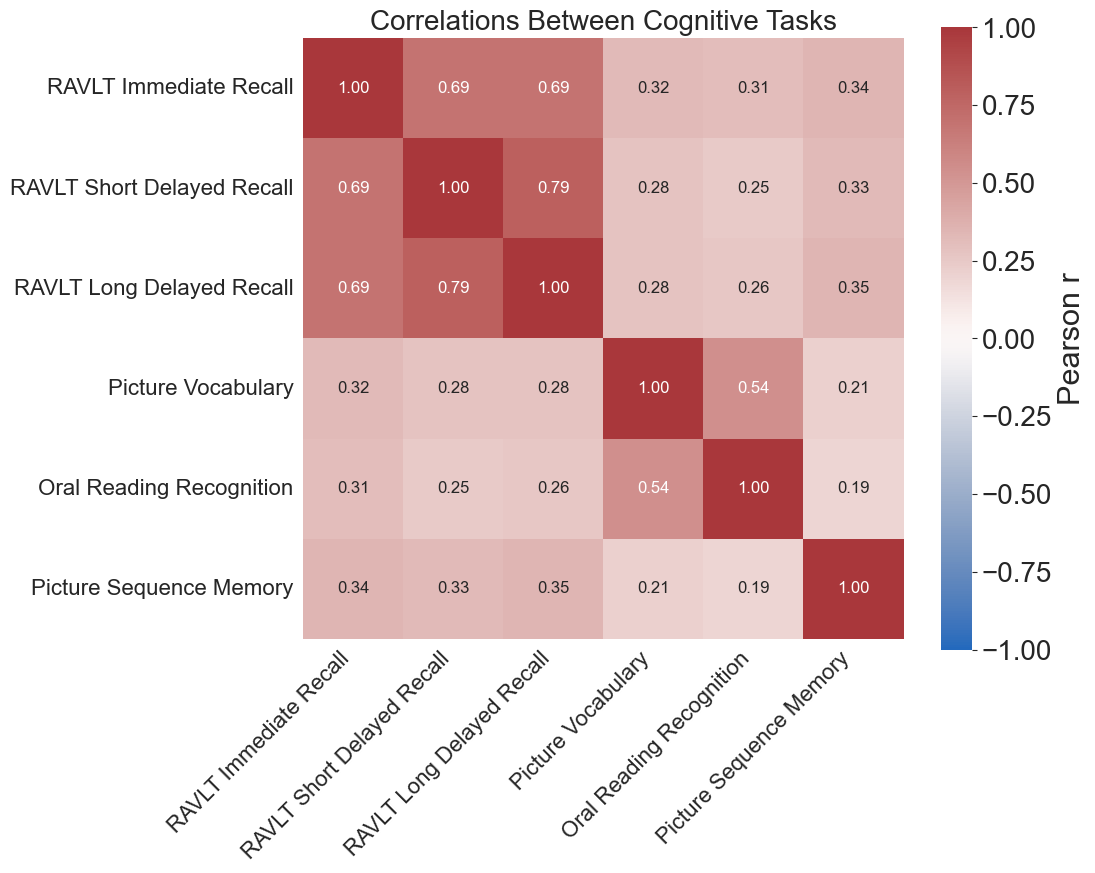

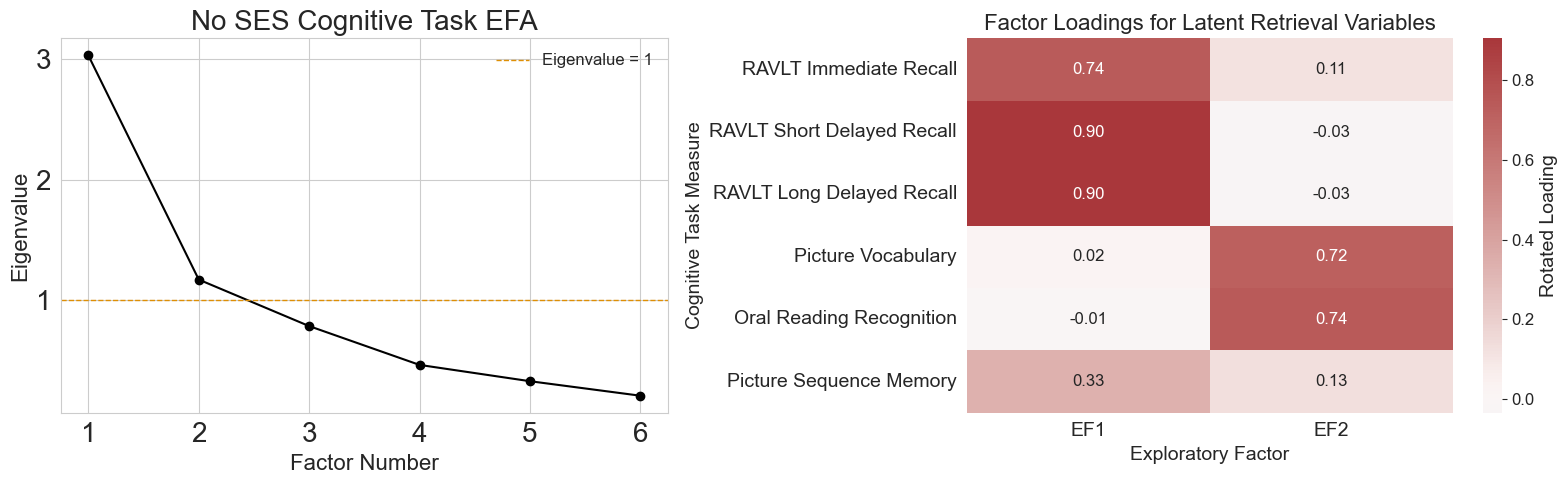


SES residualization
Cognitive covariates: ['interview_age', 'demo_sex_v2', 'site_id_l', 'ehi1b', 'inr']
ses_cognitive EFA complete cases: 2072/2472

Cognitive EFA diagnostics:


,score_prefix,n_complete,n_measures,n_factors,factor_selection_rule,rotation,method,bartlett_chi_square,bartlett_p_value,kmo_overall
0,ses_cognitive,2072,6,2,kaiser_eigenvalue_gt_1,oblimin,ml,4731.447989,0.0,0.767396



Cognitive EFA eigenvalues:


,component,eigenvalue,common_factor_eigenvalue,retained_by_kaiser_rule
0,1,2.945915,2.648513,True
1,2,1.203684,0.984613,True
2,3,0.800323,0.091206,False
3,4,0.499024,0.005303,False
4,5,0.340699,-0.000704,False
5,6,0.210355,-0.004083,False



Cognitive EFA variance:


...

,ses_cognitive_EF1,ses_cognitive_EF2
ravlt_immediate_2y_ses_resid,0.735089,0.108464
ravlt_short_delay_2y_ses_resid,0.890866,-0.028413
ravlt_long_delay_2y_ses_resid,0.907110,-0.031146
nihtbx_picvocab_uncorrected_2y_ses_resid,0.030786,0.670883
nihtbx_reading_uncorrected_2y_ses_resid,-0.016570,0.741136
nihtbx_picture_uncorrected_2y_ses_resid,0.342511,0.099909



Cognitive EFA measure diagnostics:


,communality,uniqueness,kmo
ravlt_immediate_2y_ses_resid,0.552121,0.447879,0.852258
ravlt_short_delay_2y_ses_resid,0.794449,0.205551,0.749054
ravlt_long_delay_2y_ses_resid,0.823819,0.176181,0.742886
nihtbx_picvocab_uncorrected_2y_ses_resid,0.451032,0.548968,0.691884
nihtbx_reading_uncorrected_2y_ses_resid,0.549557,0.450443,0.677153
nihtbx_picture_uncorrected_2y_ses_resid,0.127295,0.872705,0.937187


Correlations Between Cognitive Tasks


,ravlt_immediate_2y_ses_resid,ravlt_short_delay_2y_ses_resid,ravlt_long_delay_2y_ses_resid,nihtbx_picvocab_uncorrected_2y_ses_resid,nihtbx_reading_uncorrected_2y_ses_resid,nihtbx_picture_uncorrected_2y_ses_resid
ravlt_immediate_2y_ses_resid,1.000000,0.678848,0.689274,0.286240,0.283996,0.331172
ravlt_short_delay_2y_ses_resid,0.678848,1.000000,0.789649,0.254123,0.220971,0.323117
ravlt_long_delay_2y_ses_resid,0.689274,0.789649,1.000000,0.244289,0.235363,0.337086
nihtbx_picvocab_uncorrected_2y_ses_resid,0.286240,0.254123,0.244289,1.000000,0.505267,0.180092
nihtbx_reading_uncorrected_2y_ses_resid,0.283996,0.220971,0.235363,0.505267,1.000000,0.157268
nihtbx_picture_uncorrected_2y_ses_resid,0.331172,0.323117,0.337086,0.180092,0.157268,1.000000


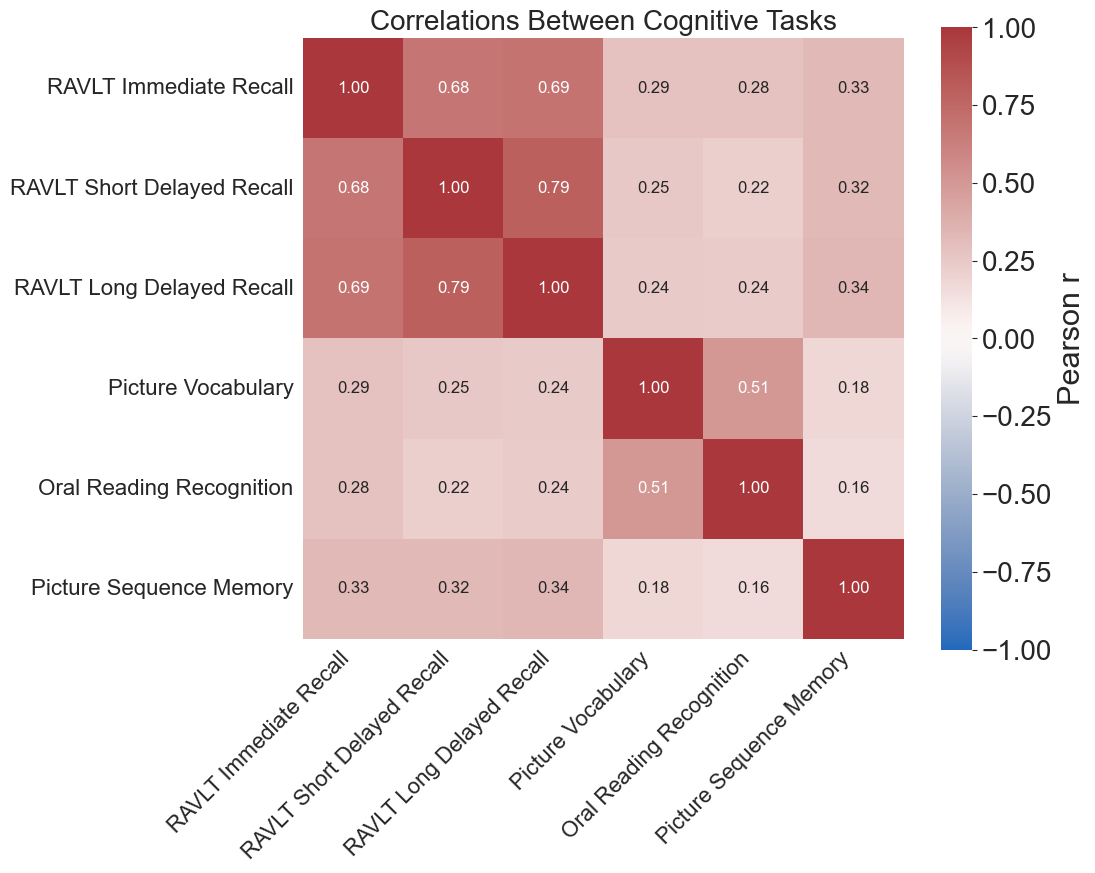

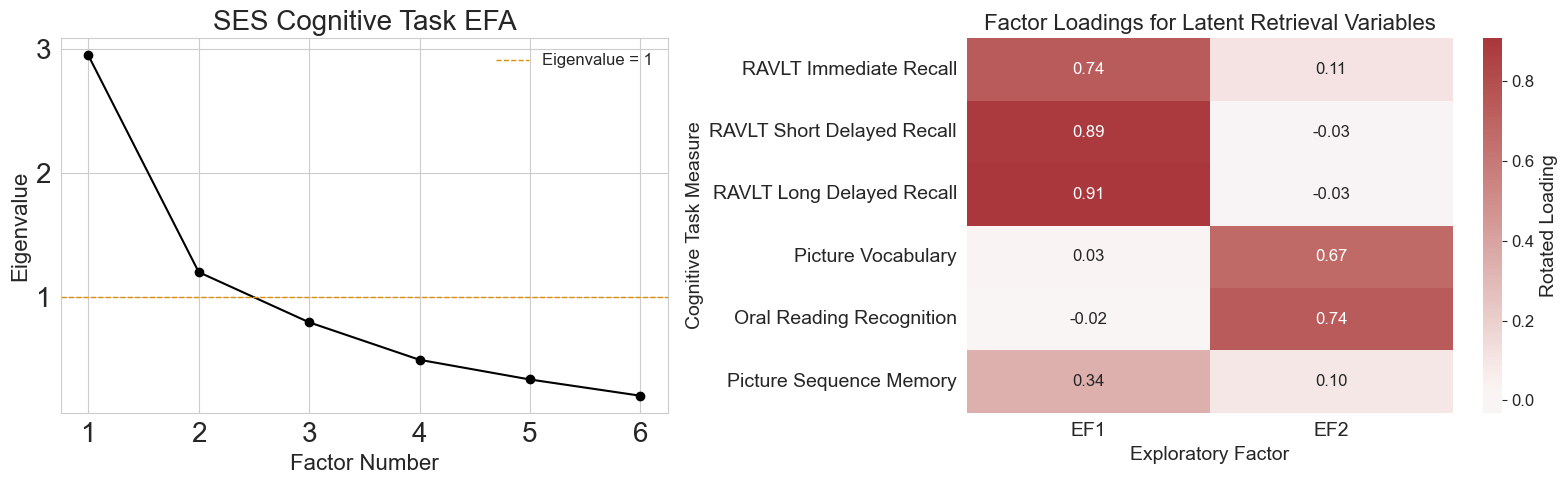

In [23]:
efa_model_outputs = {}

for spec in EFA_MODEL_SPECS:
    print()
    print('=' * 90)
    print(spec['label'])
    print('=' * 90)
    print('Cognitive covariates:', spec['cognitive_covariates'])

    df, cognitive_resid_cols = residualize_cognitive_variant(
        df,
        COGNITIVE_TASK_MEASURES,
        covariates=spec['cognitive_covariates'],
        output_suffix=spec['prefix'],
    )
    task_labels = task_labels_for_residual_cols(cognitive_resid_cols, spec['prefix'])

    cognitive_efa_result = fit_efa_scores(
        df,
        cognitive_resid_cols,
        score_prefix=f"{spec['prefix']}_cognitive",
        n_factors=EFA_N_FACTORS,
        rotation=EFA_ROTATION,
        method=EFA_METHOD,
    )
    df = attach_score_columns(df, cognitive_efa_result['scores'])

    print()
    print('Cognitive EFA diagnostics:')
    display(cognitive_efa_result['diagnostics'])
    print()
    print('Cognitive EFA eigenvalues:')
    display(cognitive_efa_result['eigenvalues'])
    print()
    print('Cognitive EFA variance:')
    display(cognitive_efa_result['variance'])
    print()
    print('Cognitive EFA rotated loadings:')
    display(cognitive_efa_result['loadings'])
    print()
    print('Cognitive EFA measure diagnostics:')
    display(cognitive_efa_result['measure_diagnostics'].join(cognitive_efa_result['kmo_per_item']))

    plot_cognitive_measure_correlations(
        cognitive_efa_result['input'],
        cognitive_resid_cols,
        task_labels,
        title='Correlations Between Cognitive Tasks',
    )
    plot_cognitive_efa_summary(
        cognitive_efa_result,
        task_labels,
        title=f"{spec['short_label']} Cognitive Task EFA",
    )

    efa_model_outputs[spec['model_name']] = {
        'spec': spec,
        'cognitive_resid_cols': cognitive_resid_cols,
        'task_labels': task_labels,
        'cognitive_efa': cognitive_efa_result,
    }

no_ses_model = efa_model_outputs['without_ses_residualization']
ses_model = efa_model_outputs['with_ses_residualization']

## Export Task EFA Scores

In [24]:
for model_name, model_output in efa_model_outputs.items():
    scores_path = EFA_RESULTS_DIR / f'efa_cognitive_scores_{model_name}.csv'
    scores = df[['src_subject_id']].join(model_output['cognitive_efa']['scores'])
    scores.to_csv(scores_path, index=False)
    print(f'Saved {scores_path}')

Saved /Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/efa_results/efa_cognitive_scores_without_ses_residualization.csv
Saved /Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/efa_results/efa_cognitive_scores_with_ses_residualization.csv
